# Análise hospitalar com CRISP-DM
Análise descritiva de registros de AIH e leitos cadastrados no Distrito Federal, competência de junho de 2025. As células organizam a leitura dos dados, a execução das verificações e a apresentação dos gráficos.

In [1]:
from pathlib import Path
import runpy
ROOT = Path.cwd()
if not (ROOT / 'src/gerar_graficos.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/gerar_graficos.py').exists(), 'Abra o notebook dentro da pasta do projeto.'

## Entendimento e preparação
Cada linha é um estabelecimento em uma competência. Preservamos CNES como texto.

In [2]:
import pandas as pd
df = pd.read_csv(ROOT / 'dados/integracao_por_estabelecimento.csv', dtype={'CNES':'string', 'COMPETEN':'string'})
df.head()

,CNES,COMPETEN,registros_rd,aih_normais,aih_continuacao,dias_permanencia_registrados,obitos_registrados,valor_total_centavos,QT_EXIST,QT_SUS,QT_NSUS,TP_UNID,NAT_JUR
0,0010456,202506,2511,2511,0,17943,144,759038295,888,888,0,5,3077
1,0010464,202506,1170,1170,0,8462,38,128310292,353,320,33,5,1023
2,0010472,202506,1654,1654,0,8962,26,143601238,421,413,8,5,1023
3,0010480,202506,2588,2588,0,12551,54,151287725,554,533,21,5,1023
4,0010499,202506,1707,1707,0,10772,30,157988304,459,433,26,5,1023


In [3]:
df.info()
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   CNES                          32 non-null     string
 1   COMPETEN                      32 non-null     string
 2   registros_rd                  32 non-null     int64 
 3   aih_normais                   32 non-null     int64 
 4   aih_continuacao               32 non-null     int64 
 5   dias_permanencia_registrados  32 non-null     int64 
 6   obitos_registrados            32 non-null     int64 
 7   valor_total_centavos          32 non-null     int64 
 8   QT_EXIST                      32 non-null     int64 
 9   QT_SUS                        32 non-null     int64 
 10  QT_NSUS                       32 non-null     int64 
 11  TP_UNID                       32 non-null     int64 
 12  NAT_JUR                       32 non-null     int64 
dtypes: int64(11), string(2

## Análise e avaliação
Executar o mesmo script mantém uma única definição dos cálculos. As verificações interrompem a geração se falharem.

In [4]:
resultado = runpy.run_path(str(ROOT / 'src/gerar_graficos.py'), run_name='__main__')

{
  "estabelecimentos": 32,
  "registros_aih": 21120,
  "aih_normais": 21036,
  "aih_prorrogacao": 84,
  "valor_total_centavos": 3397297919,
  "leitos_sus_recorte": 5499,
  "leitos_existentes_recorte": 6449,
  "maior_volume_cnes": "0010480",
  "maior_volume_registros": 2588,
  "participacao_dez_maiores_percentual": 77.58996212121212
}


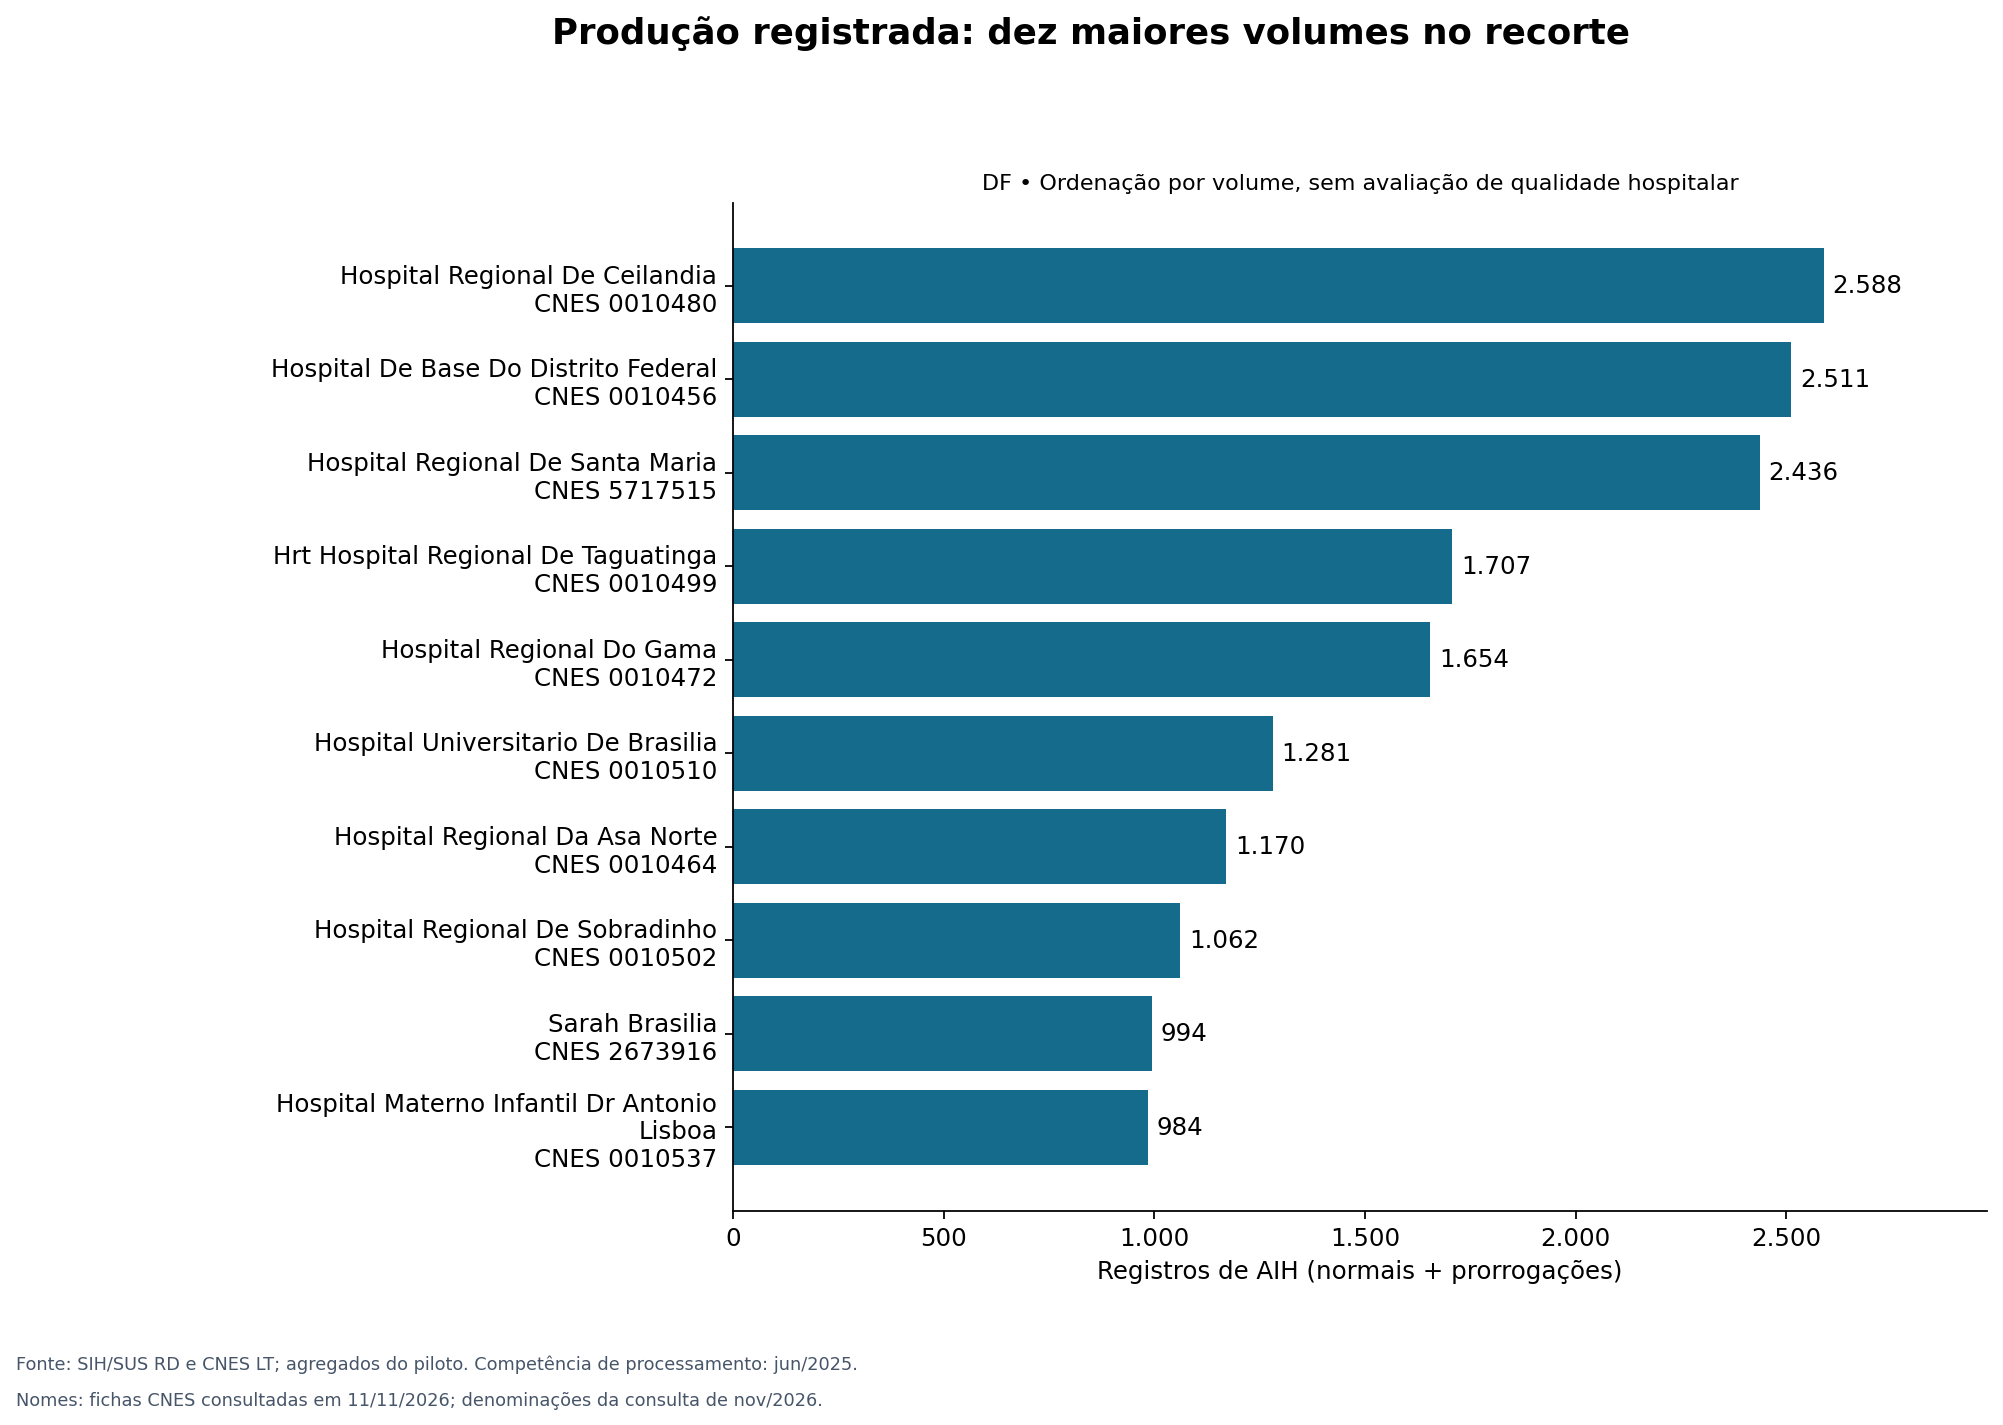

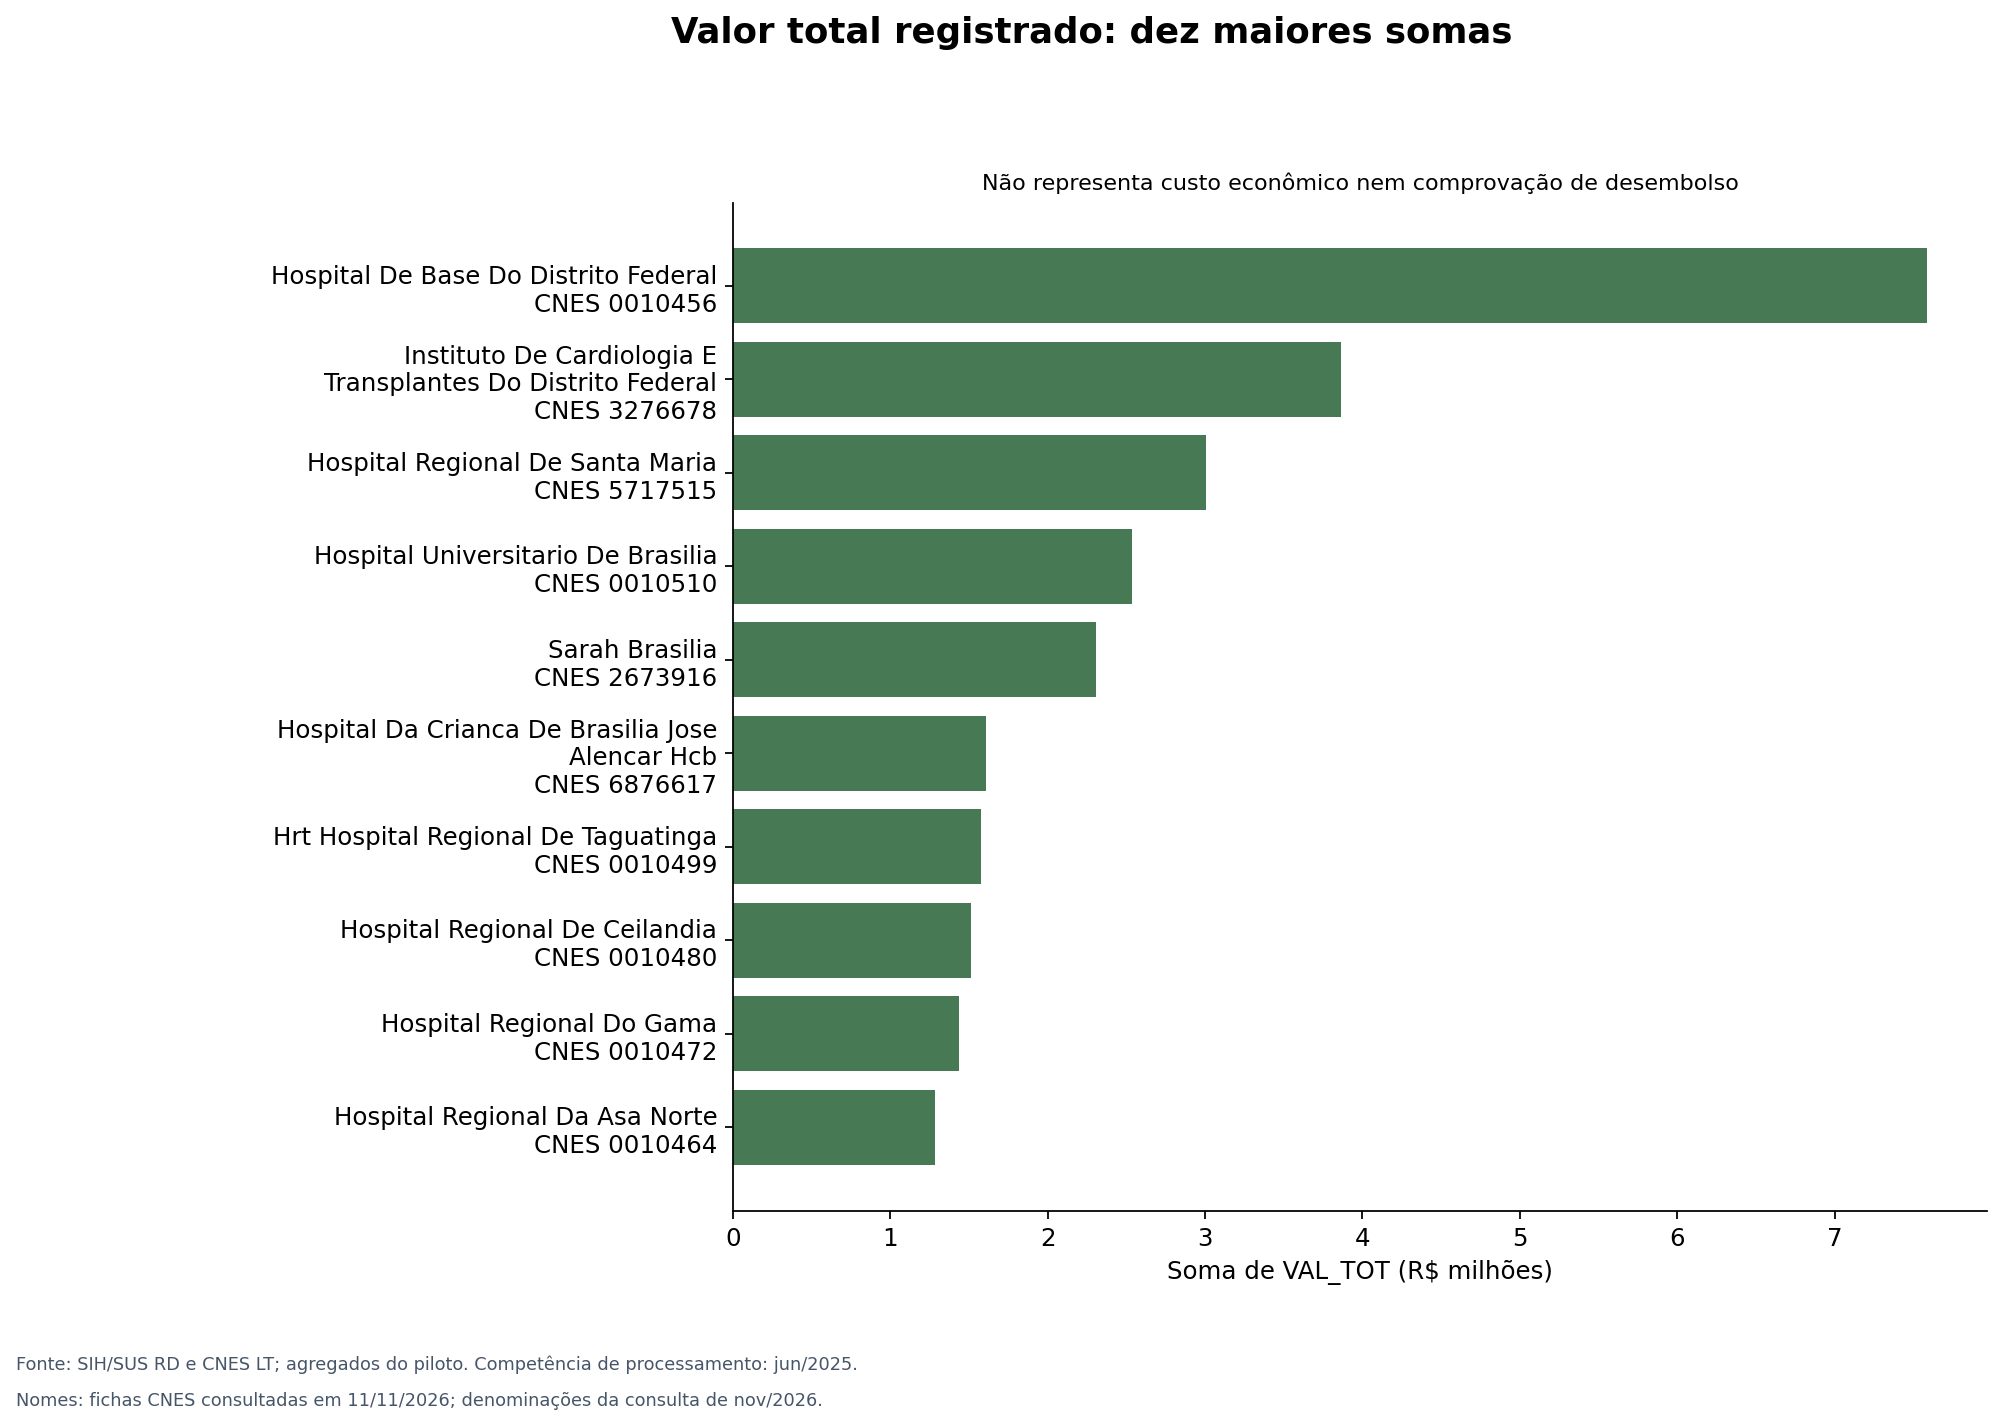

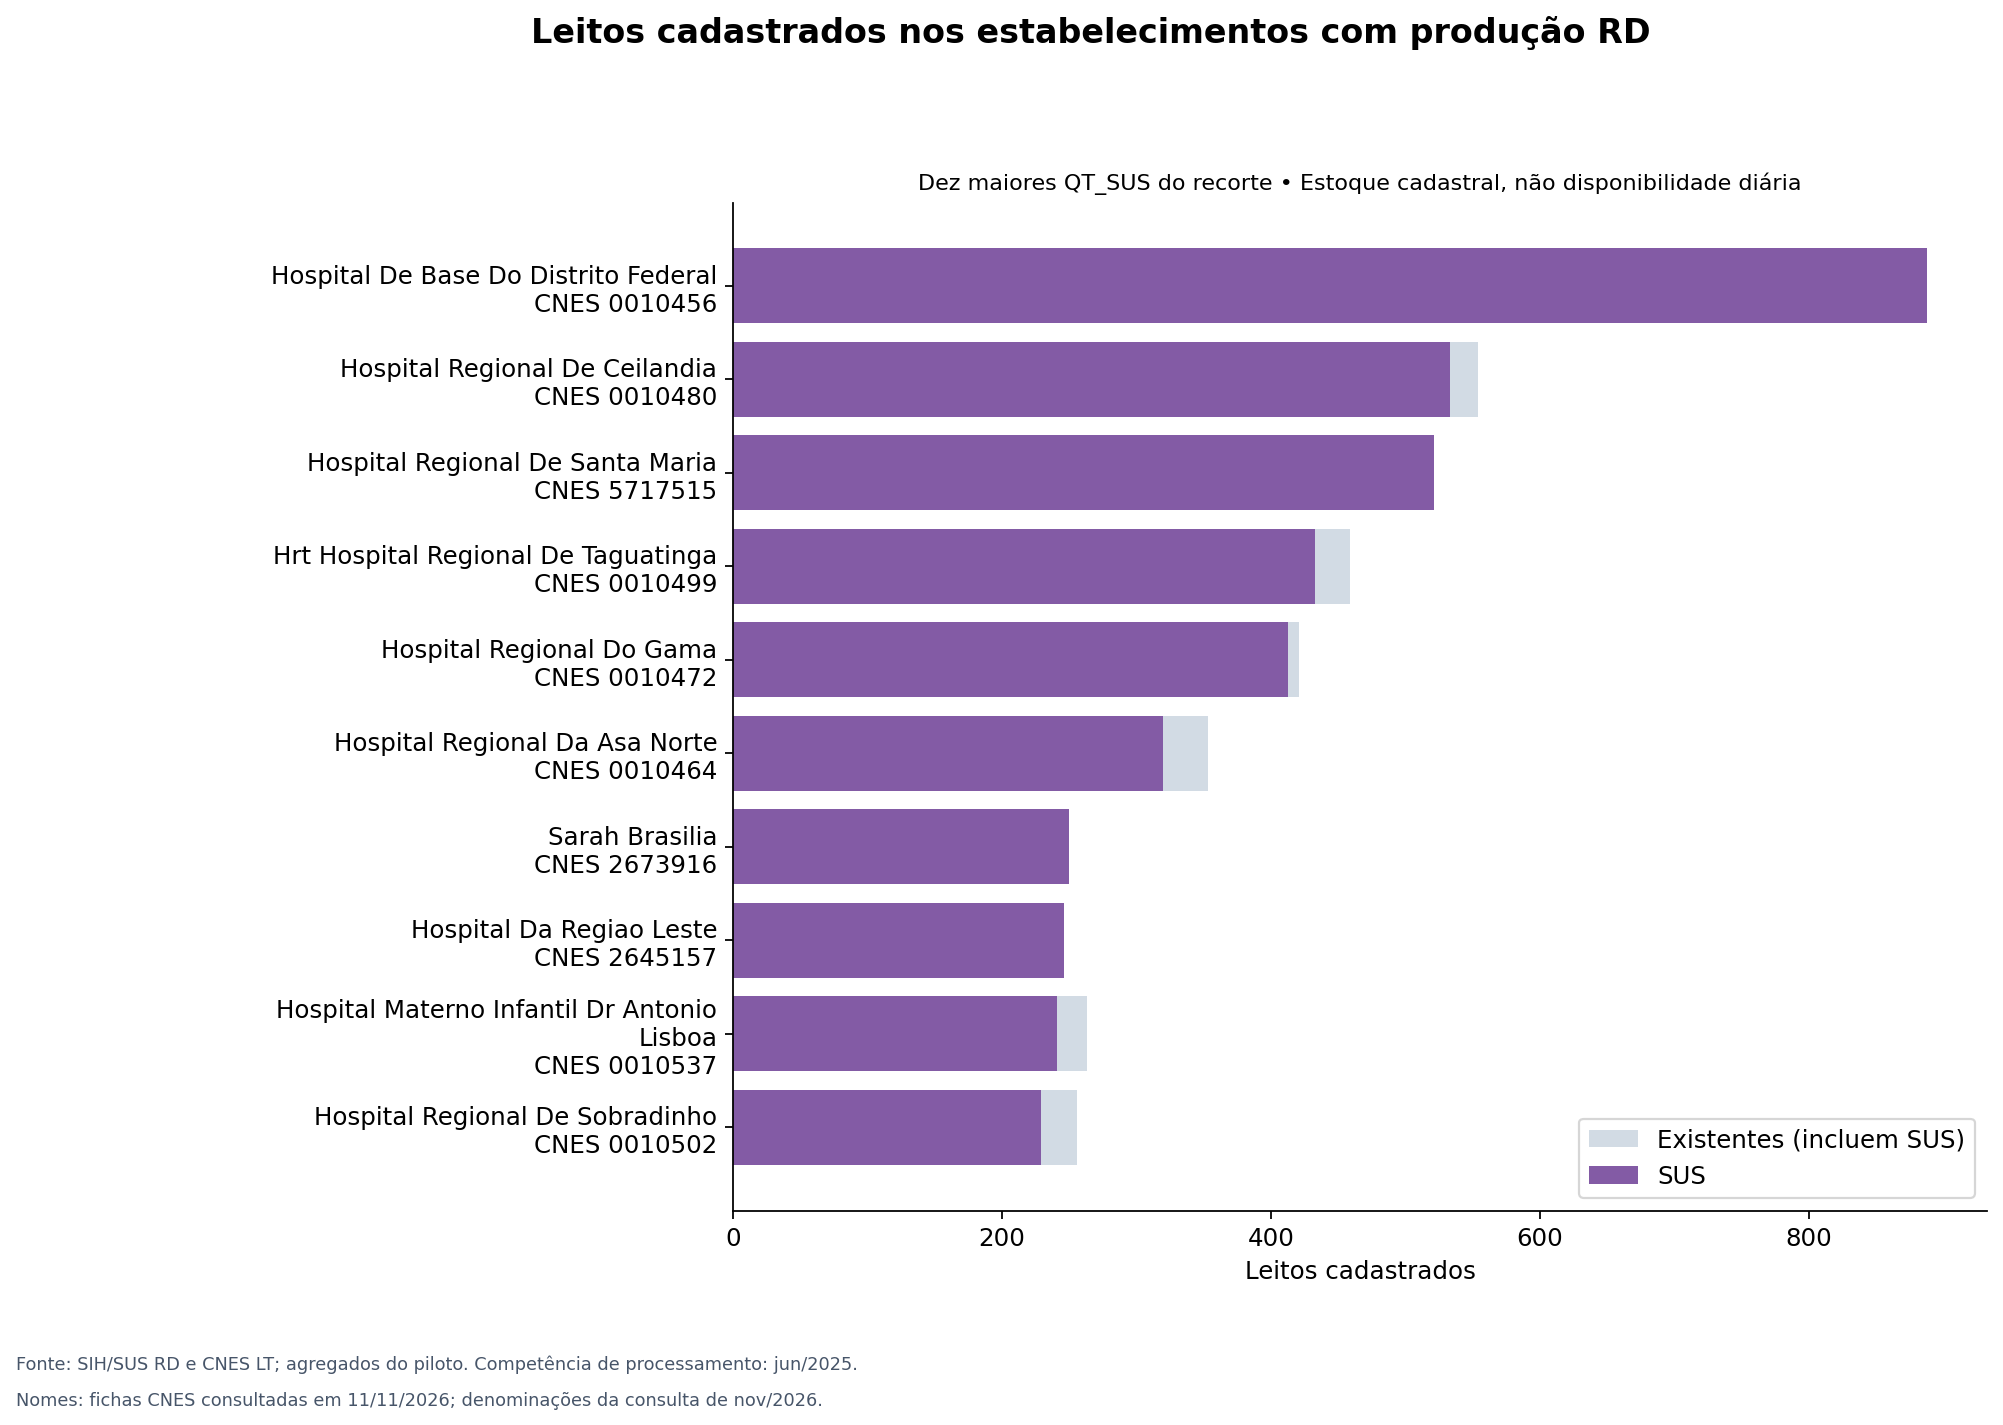

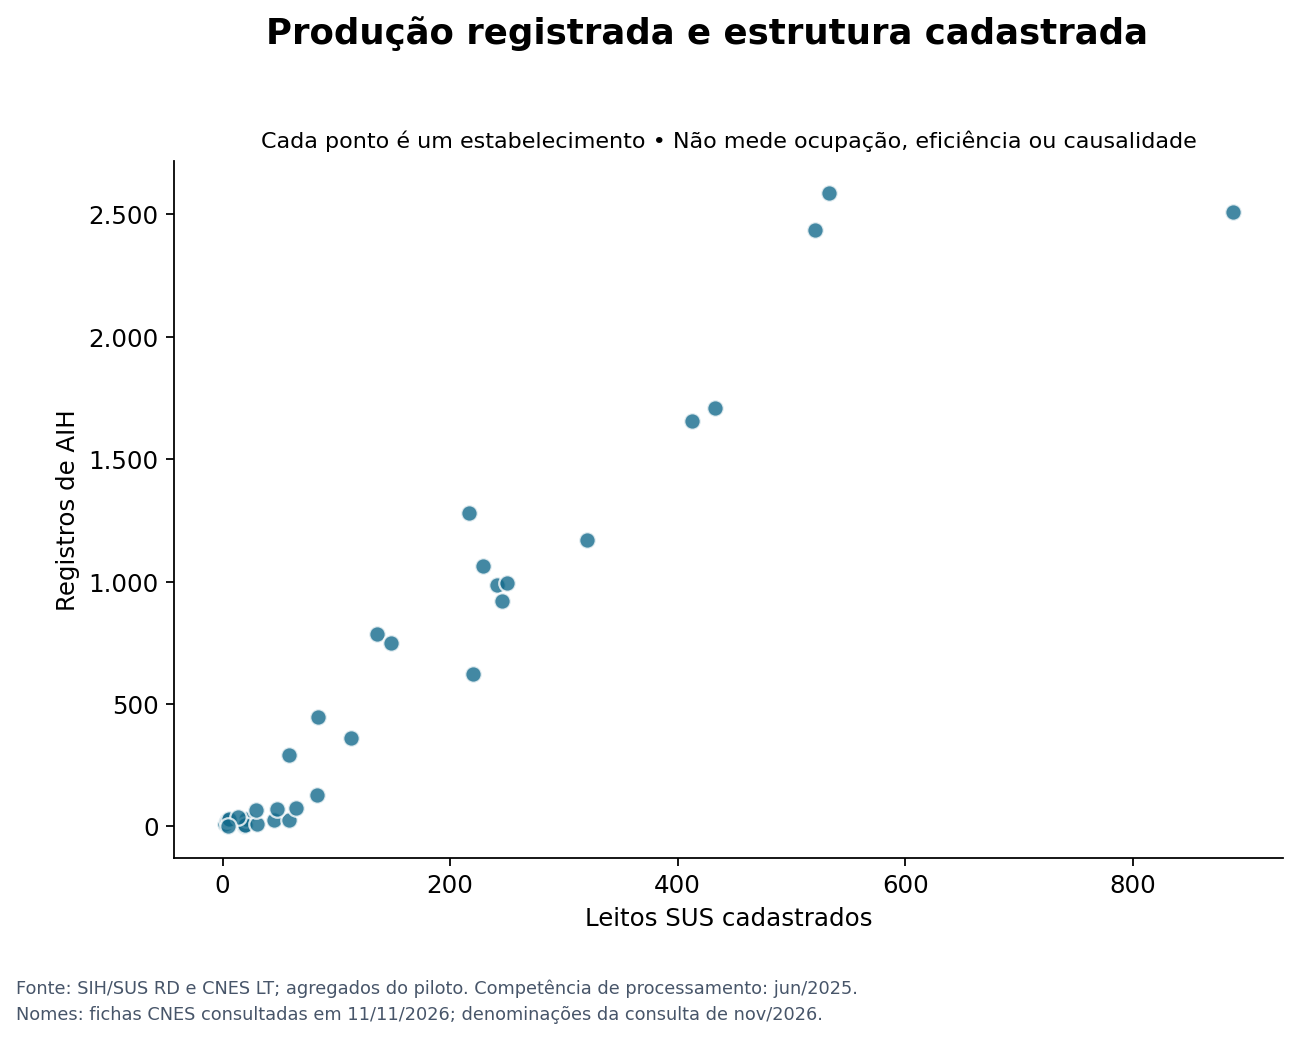

In [5]:
from IPython.display import Image, display
for arquivo in sorted((ROOT / 'graficos').glob('*.png')):
    display(Image(filename=str(arquivo)))

## Interpretação e implementação
O relatório reúne os resultados quantitativos e os limites de interpretação da análise.

In [6]:
from IPython.display import Markdown
display(Markdown((ROOT / 'docs/resultados_e_limitacoes.md').read_text(encoding='utf-8')))

# Resultados da análise

Análise descritiva dos registros de produção hospitalar e leitos cadastrados no Distrito Federal.

O recorte inclui 32 estabelecimentos, 21120 registros de AIH, sendo 21036 normais e 84 prorrogações. O maior volume é de Hospital Regional De Ceilandia (CNES 0010480), com 2588 registros. Os dez maiores volumes concentram 77.59% dos registros do recorte.

A soma de VAL_TOT é R$ 33972979.19. Os estabelecimentos com produção no RD totalizam 5499 leitos SUS cadastrados e 6449 existentes. Esse universo não corresponde a todos os estabelecimentos do LT.

## Interpretação dos gráficos

1. Barras de produção: permitem comparar volume registrado e identificar concentração. O gráfico mostra apenas os dez maiores, mas os totais usam a base completa. Volume não é qualidade.
2. Barras monetárias: comparam somas administrativas. Diferenças podem refletir volume e composição dos procedimentos; não demonstram eficiência ou custo hospitalar.
3. Barras de leitos: mostram capacidade cadastrada do subuniverso com produção. Leitos SUS estão contidos nos existentes, por isso as barras não são somadas.
4. Dispersão: permite explorar a distribuição conjunta de volume e leitos. Não demonstra relação causal e não é taxa de ocupação.

## Limitações

Uma competência de processamento não representa exatamente internações iniciadas naquele mês. Registros não representam pessoas únicas. Há diferenças entre especialidades e perfis de atendimento não controladas nesta análise. Os gráficos exibem nomes consultados nas fichas oficiais do CNES em 11/11/2026, mantendo os códigos. As denominações correspondem à consulta de novembro/2026 e não constituem um cadastro histórico de junho/2025. Os rótulos não alteram o universo nem os valores. O estudo é descritivo, sem inferência estatística, previsão ou avaliação com usuários. A avaliação de dados se limita à consistência interna, sem conciliação independente com TABNET. Os testes comparam o CSV a evidências do mesmo piloto: consistência interna não é validação externa.

## Figuras

![01_registros_por_estabelecimento](../graficos/01_registros_por_estabelecimento.png)

![02_valor_por_estabelecimento](../graficos/02_valor_por_estabelecimento.png)

![03_leitos_cadastrados](../graficos/03_leitos_cadastrados.png)

![04_producao_e_leitos](../graficos/04_producao_e_leitos.png)
